# 02 – Federated Learning mit IID-Daten (Task 2)

Dasselbe MLP wie in Notebook 01 wird jetzt föderiert trainiert (Flower, FedAvg). Die Trainingsdaten werden **gleichmäßig und stratifiziert** auf die Clients verteilt (IID).

Fragen:
1. Erreicht FL die zentrale Baseline (Test-Accuracy 0.855)?
2. Wie wirkt sich die Anzahl der Clients aus (2, 5, 10, 20)?
3. Welche Hyperparameter (lokale Epochen, Batchgröße, Lernrate, Anteil Clients pro Runde) helfen?
4. Ist FL besser als die lokalen Baselines?

**Ablauf einer Runde:** Server schickt globales Modell → jeder Client trainiert `E` lokale Epochen auf 85 % seiner Daten → Server bildet den gewichteten Mittelwert (FedAvg) → Auswertung des globalen Modells auf Val- und Testset.

**Methodik:** Hyperparameter werden auf dem **Validierungsset** gewählt, das Testset dient nur dem finalen Vergleich. Runde 0 = zufällig initialisiertes Startmodell.

Jeder Lauf wird in `results/02/` gespeichert. Beim erneuten Ausführen werden fertige Läufe geladen statt neu gerechnet (`FORCE = True` erzwingt Neuberechnung).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fl import run_fl

ROUNDS = 30
SEEDS = [42, 43, 44]
FORCE = False
OUT = Path("results/02"); OUT.mkdir(parents=True, exist_ok=True)

base = json.loads(Path("results/01_baselines.json").read_text())
CENTRAL_ACC = base["central"]["mean"]["accuracy"]
CENTRAL_F1 = base["central"]["mean"]["f1"]
LOCAL = {k: v["mean"] for k, v in base["local"].items()}
print(f"Zentral: Acc {CENTRAL_ACC:.4f}, F1 {CENTRAL_F1:.4f}")


def run(name, **kw):
    """FL-Lauf mit Cache. kw wird an run_fl durchgereicht."""
    f = OUT / f"{name}.csv"
    if f.exists() and not FORCE:
        return pd.read_csv(f)
    h = run_fl(**kw)
    for k, v in h.attrs.items():
        h[k] = v
    h.to_csv(f, index=False)
    print(f"{name}: {h.runtime_s.iloc[0]:.0f}s, Test-Acc letzte Runde {h.test_accuracy.iloc[-1]:.4f}")
    return h


def last(h, col="test_accuracy", k=1):
    """Mittel über die letzten k Runden."""
    return h[col].iloc[-k:].mean()

Zentral: Acc 0.8546, F1 0.6595


## 1. Anzahl der Clients

Feste Einstellung wie im zentralen Training: Adam, Lernrate 0.001, Batchgröße 64, **1 lokale Epoche pro Runde**, alle Clients nehmen an jeder Runde teil.

In [2]:
N_CLIENTS = [2, 5, 10, 20]
runs_n = {n: run(f"iid_n{n}_E1", partition="iid", n_clients=n, num_rounds=ROUNDS, local_epochs=1)
          for n in N_CLIENTS}

(raylet) Stack (most recent call first):
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_configWindows fatal exception: access violation
(raylet) 
(raylet) 
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown
(raylet)   File Stack (most recent call first):
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet) "  File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.pyc:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 1170 in wrapper
(raylet)   File ""c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private

iid_n2_E1: 70s, Test-Acc letzte Runde 0.8539


(raylet) Stack (most recent call first):
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 1170 in wrapper
(ClientAppActor pid=6632) WARNING :   Manually terminating ClientAppActor
(raylet) Stack (most recent call first): [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\sit

iid_n5_E1: 73s, Test-Acc letzte Runde 0.8535


(raylet) Stack (most recent call first):
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 1170 in wrapper
(ClientAppActor pid=36624) WARNING :   Manually terminating ClientAppActor
(raylet) Stack (most recent call first): [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\si

iid_n10_E1: 78s, Test-Acc letzte Runde 0.8511


(raylet) Stack (most recent call first):
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 1170 in wrapper
(ClientAppActor pid=39084) WARNING :   Manually terminating ClientAppActor
(raylet) Stack (most recent call first): [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\si

iid_n20_E1: 87s, Test-Acc letzte Runde 0.8496


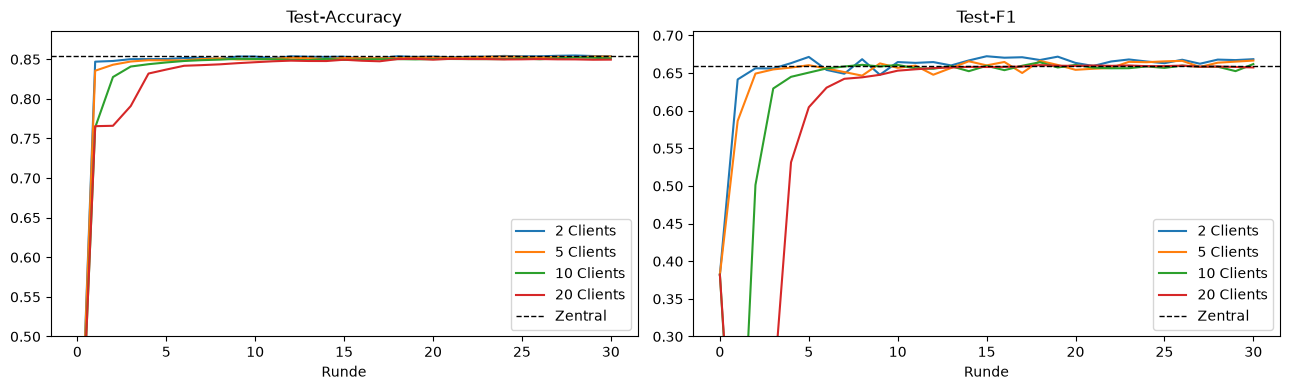

,Test-Acc (letzte Runde),Test-F1,Lokal (Acc),Laufzeit [s]
2,0.8539,0.6684,0.8509,70.3
5,0.8535,0.6666,0.8465,72.6
10,0.8511,0.6619,0.8445,78.5
20,0.8496,0.6574,0.8398,86.8


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for n, h in runs_n.items():
    ax[0].plot(h["round"], h.test_accuracy, label=f"{n} Clients")
    ax[1].plot(h["round"], h.test_f1, label=f"{n} Clients")
for a, c, t in [(ax[0], CENTRAL_ACC, "Test-Accuracy"), (ax[1], CENTRAL_F1, "Test-F1")]:
    a.axhline(c, color="k", ls="--", lw=1, label="Zentral")
    a.set(title=t, xlabel="Runde", ylim=(0.5 if "Acc" in t else 0.3, None)); a.legend()
plt.tight_layout(); plt.savefig(OUT / "clients_curves.png", dpi=150); plt.show()

pd.DataFrame({n: {"Test-Acc (letzte Runde)": last(h), "Test-F1": last(h, "test_f1"),
                  "Lokal (Acc)": LOCAL.get(f"IID, {n} Clients", {}).get("accuracy"),
                  "Laufzeit [s]": h.runtime_s.iloc[0]} for n, h in runs_n.items()}).T.round(4)

Mit mehr Clients hat jeder Client weniger Daten. Bei 1 lokaler Epoche macht jeder Client pro Runde entsprechend weniger Optimierungsschritte, das globale Modell lernt pro Runde langsamer. Der nächste Abschnitt prüft, ob mehr lokale Berechnung das ausgleicht.

## 2. Hyperparameter (10 Clients)

Ausgehend von der Grundeinstellung wird jeweils **ein** Parameter verändert. Auswahlkriterium: mittlere **Val-Accuracy der letzten 5 Runden**.

| Parameter | Werte |
|---|---|
| lokale Epochen E | 1, 2, 5 |
| Batchgröße B | 32, 64, 128 |
| Lernrate | 0.0003, 0.001, 0.003 |
| Anteil Clients pro Runde | 0.5, 1.0 |

In [4]:
N = 10
grid = {
    "E1 (Basis)": dict(local_epochs=1),
    "E2": dict(local_epochs=2),
    "E5": dict(local_epochs=5),
    "B32": dict(batch_size=32),
    "B128": dict(batch_size=128),
    "lr0.0003": dict(lr=3e-4),
    "lr0.003": dict(lr=3e-3),
    "50% Clients/Runde": dict(fraction_train=0.5),
}
runs_hp = {}
for name, kw in grid.items():
    fname = "iid_n10_" + name.split(" ")[0].replace("%", "pct").replace("/", "")
    runs_hp[name] = (runs_n[N] if name == "E1 (Basis)"
                     else run(fname, partition="iid", n_clients=N, num_rounds=ROUNDS, **kw))

hp = pd.DataFrame({name: {"Val-Acc (letzte 5)": last(h, "val_accuracy", 5),
                          "Test-Acc (letzte)": last(h), "Test-F1 (letzte)": last(h, "test_f1"),
                          "Max Val-Acc": h.val_accuracy.max(),
                          "Runde Max": int(h.loc[h.val_accuracy.idxmax(), "round"])}
                   for name, h in runs_hp.items()}).T
hp.sort_values("Val-Acc (letzte 5)", ascending=False).round(4)

(raylet) Stack (most recent call first):
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 1170 in wrapper
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in 
(raylet) shutdown
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py"Windows fatal exception: access violation
(raylet) 
(raylet)   File , line 2114 in shutdown
(raylet)   File ""c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 1170627 in job_lo

iid_n10_E2: 77s, Test-Acc letzte Runde 0.8535


(raylet) Stack (most recent call first):
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 1170 in wrapper
(ClientAppActor pid=20588) WARNING :   Manually terminating ClientAppActor
(raylet) Stack (most recent call first): [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\si

iid_n10_E5: 78s, Test-Acc letzte Runde 0.8515


(raylet) Stack (most recent call first):
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 1170 in wrapper
(ClientAppActor pid=25180) WARNING :   Manually terminating ClientAppActor
(raylet) Stack (most recent call first): [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\si

iid_n10_B32: 76s, Test-Acc letzte Runde 0.8525


... (5 outputs left out)

iid_n10_lr0.003: 78s, Test-Acc letzte Runde 0.8527


(raylet) Stack (most recent call first):
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 1170 in wrapper
(raylet) Stack (most recent call first): [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown [repeated 31x ac

iid_n10_50pct: 71s, Test-Acc letzte Runde 0.8511


,Val-Acc (letzte 5),Test-Acc (letzte),Test-F1 (letzte),Max Val-Acc,Runde Max
E5,0.8587,0.8515,0.6542,0.8596,30.0
E2,0.8572,0.8535,0.6627,0.8579,22.0
B32,0.8567,0.8525,0.6598,0.8579,30.0
lr0.003,0.8562,0.8527,0.6603,0.8583,20.0
E1 (Basis),0.8558,0.8511,0.6619,0.8567,27.0
50% Clients/Runde,0.8553,0.8511,0.6590,0.8565,30.0
B128,0.8537,0.8496,0.6618,0.8549,25.0
lr0.0003,0.8506,0.8499,0.6588,0.8514,29.0


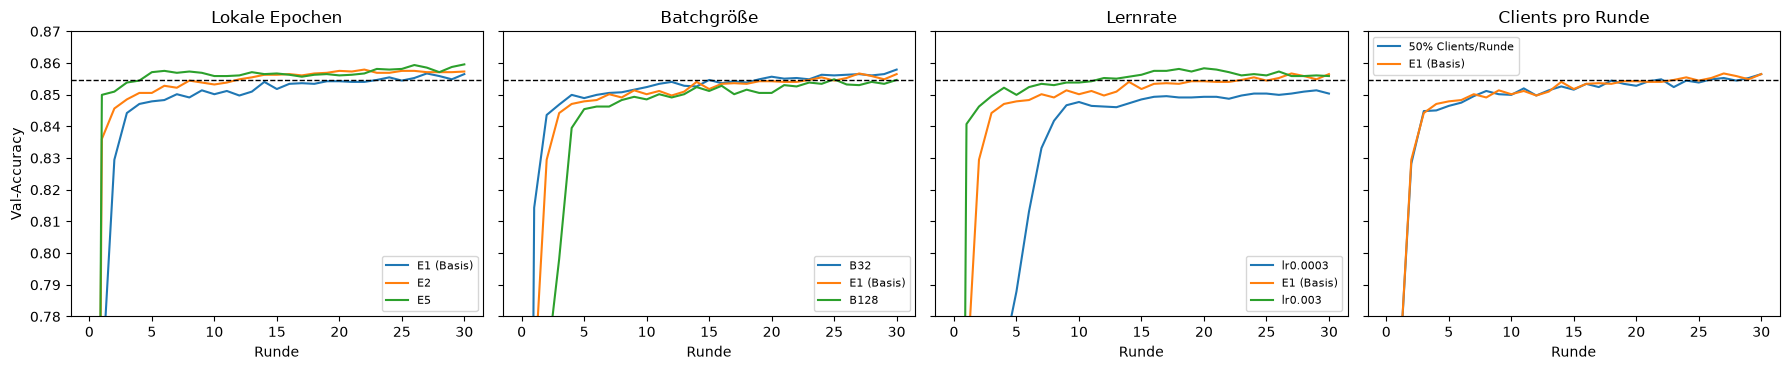

In [5]:
groups = {"Lokale Epochen": ["E1 (Basis)", "E2", "E5"],
          "Batchgröße": ["B32", "E1 (Basis)", "B128"],
          "Lernrate": ["lr0.0003", "E1 (Basis)", "lr0.003"],
          "Clients pro Runde": ["50% Clients/Runde", "E1 (Basis)"]}
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for a, (title, names) in zip(ax, groups.items()):
    for nme in names:
        a.plot(runs_hp[nme]["round"], runs_hp[nme].val_accuracy, label=nme)
    a.axhline(CENTRAL_ACC, color="k", ls="--", lw=1)
    a.set(title=title, xlabel="Runde", ylim=(0.78, 0.87)); a.legend(fontsize=8)
ax[0].set_ylabel("Val-Accuracy")
plt.tight_layout(); plt.savefig(OUT / "hyperparams.png", dpi=150); plt.show()

## 3. Beste Einstellung für alle Clientzahlen, 3 Seeds

Die auf dem Validierungsset beste Einstellung wird für 2, 5, 10 und 20 Clients mit drei Seeds wiederholt (Seed = Modellinitialisierung und Reihenfolge im lokalen Training; die Partition bleibt gleich).

In [6]:
best_name = hp["Val-Acc (letzte 5)"].idxmax()
best_kw = grid[best_name]
print("Beste Einstellung:", best_name, best_kw)

final = []
curves = {}
for n in N_CLIENTS:
    for s in SEEDS:
        tag = "_".join(f"{k}{v}" for k, v in best_kw.items())
        h = run(f"iid_n{n}_best_{tag}_s{s}", partition="iid", n_clients=n,
                num_rounds=ROUNDS, seed=s, **best_kw)
        curves[(n, s)] = h
        final.append({"n_clients": n, "seed": s, "test_acc": last(h), "test_f1": last(h, "test_f1"),
                      "test_auc": last(h, "test_roc_auc"), "test_bal_acc": last(h, "test_balanced_acc")})
final = pd.DataFrame(final)

Beste Einstellung: E5 {'local_epochs': 5}


(raylet) Stack (most recent call first):
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 1170 in wrapper
(raylet) Stack (most recent call first): [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown [repeated 31x ac

iid_n2_best_local_epochs5_s42: 79s, Test-Acc letzte Runde 0.8494


(raylet) Stack (most recent call first):
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 1170 in wrapper
(raylet) Stack (most recent call first): [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown [repeated 31x ac

iid_n2_best_local_epochs5_s43: 77s, Test-Acc letzte Runde 0.8491


(raylet) Stack (most recent call first):
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 1170 in wrapper
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py"  File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet) , line 627 in job_logging_config
(ClientAppActor pid=16068) WARNING :   Manually terminating ClientAppActor
(raylet) Stack (most recent call first): [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_

... (15 outputs left out)

(raylet) Stack (most recent call first):
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 1170 in wrapper
(raylet) Stack (most recent call first): [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown [repeated 31x ac

iid_n20_best_local_epochs5_s43: 77s, Test-Acc letzte Runde 0.8488


(raylet) Stack (most recent call first):
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2114 in shutdown
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 1170 in wrapper
(ClientAppActor pid=30912) WARNING :   Manually terminating ClientAppActor
(raylet) Stack (most recent call first): [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\site-packages\ray\_private\worker.py", line 2789 in disconnect [repeated 31x across cluster]
(raylet)   File "c:\tmp\MDI\fmlProjekt\.venv312\Lib\si

iid_n20_best_local_epochs5_s44: 79s, Test-Acc letzte Runde 0.8493


In [7]:
def rounds_to(h, target, col="val_accuracy"):
    hit = h.loc[h[col] >= target, "round"]
    return int(hit.iloc[0]) if len(hit) else np.nan

summary = final.groupby("n_clients").agg(
    FL_acc=("test_acc", "mean"), FL_acc_std=("test_acc", "std"),
    FL_f1=("test_f1", "mean"), FL_auc=("test_auc", "mean"))
summary["Zentral_acc"] = CENTRAL_ACC
summary["Lokal_acc"] = [LOCAL[f"IID, {n} Clients"]["accuracy"] for n in summary.index]
summary["Lokal_f1"] = [LOCAL[f"IID, {n} Clients"]["f1"] for n in summary.index]
TARGET = 0.855  # Niveau des zentralen Modells
summary[f"Runden bis Val-Acc ≥ {TARGET}"] = [
    np.nanmean([rounds_to(curves[(n, s)], TARGET) for s in SEEDS]) for n in summary.index]
summary.round(4)

,FL_acc,FL_acc_std,FL_f1,FL_auc,Zentral_acc,Lokal_acc,Lokal_f1,Runden bis Val-Acc ≥ 0.855
n_clients,,,,,,,,
2,0.8484,0.0015,0.6468,0.8929,0.8546,0.8509,0.6520,1.6667
5,0.8498,0.0011,0.6552,0.8996,0.8546,0.8465,0.6538,2.3333
10,0.8498,0.0021,0.6563,0.9000,0.8546,0.8445,0.6460,4.3333
20,0.8499,0.0015,0.6613,0.9003,0.8546,0.8398,0.6401,9.0000


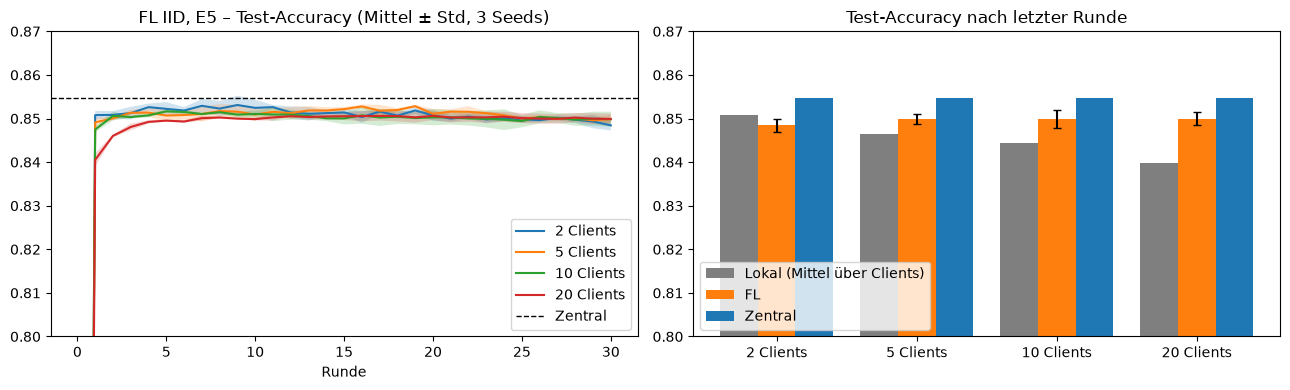

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for n in N_CLIENTS:
    acc = np.stack([curves[(n, s)].test_accuracy.to_numpy() for s in SEEDS])
    r = curves[(n, SEEDS[0])]["round"]
    ax[0].plot(r, acc.mean(0), label=f"{n} Clients")
    ax[0].fill_between(r, acc.mean(0) - acc.std(0), acc.mean(0) + acc.std(0), alpha=0.2)
ax[0].axhline(CENTRAL_ACC, color="k", ls="--", lw=1, label="Zentral")
ax[0].set(title=f"FL IID, {best_name} – Test-Accuracy (Mittel ± Std, 3 Seeds)", xlabel="Runde", ylim=(0.8, 0.87))
ax[0].legend()

x = np.arange(len(summary)); w = 0.27
ax[1].bar(x - w, summary.Lokal_acc, w, label="Lokal (Mittel über Clients)", color="tab:gray")
ax[1].bar(x, summary.FL_acc, w, yerr=summary.FL_acc_std, label="FL", color="tab:orange", capsize=3)
ax[1].bar(x + w, summary.Zentral_acc, w, label="Zentral", color="tab:blue")
ax[1].set(xticks=x, xticklabels=[f"{n} Clients" for n in summary.index], ylim=(0.8, 0.87),
          title="Test-Accuracy nach letzter Runde")
ax[1].legend(loc="lower left")
plt.tight_layout(); plt.savefig(OUT / "iid_summary.png", dpi=150); plt.show()

In [9]:
(OUT / "summary.json").write_text(json.dumps({
    "best_config": {"name": best_name, **best_kw, "rounds": ROUNDS, "seeds": SEEDS},
    "hyperparams": hp.to_dict(orient="index"),
    "summary": summary.reset_index().to_dict(orient="records"),
}, indent=2, default=float))
print("gespeichert:", OUT / "summary.json")

gespeichert: results\02\summary.json


## Beobachtungen

Zahlen aus unserem Referenzlauf (Linux). Unter Windows weichen die letzten Stellen leicht ab.

- **FL erreicht praktisch die zentrale Baseline:** Nach 30 Runden liegt die Test-Accuracy bei 0.850–0.852 (zentral 0.855), F1 bei 0.66 wie zentral. Der Rest-Abstand von 0.3–0.5 Prozentpunkten liegt in der Größenordnung der Streuung zwischen Seeds.
- **Clientzahl beeinflusst vor allem die Geschwindigkeit, kaum das Endergebnis:** Bis die Val-Accuracy 0.855 erreicht, braucht es mit 2 Clients ~3 Runden, mit 5 ~5, mit 10 ~11 und mit 20 ~25. Grund: Bei gleicher Epochenzahl macht jeder Client mit kleinerem Datenanteil weniger Optimierungsschritte, und das Mitteln vieler Modelle verlangsamt den Fortschritt pro Runde.
- **Hyperparameter:** Die Unterschiede sind klein (Val-Accuracy 0.851–0.857) und liegen teilweise im Bereich der Seed-Streuung. Nur eine zu kleine Lernrate (0.0003) fällt deutlich ab. 2 lokale Epochen waren knapp am besten; 5 Epochen bringen nicht mehr, kosten aber fast doppelte Rechenzeit. Mehr lokale Epochen bedeuten weniger Kommunikationsrunden für dasselbe Ergebnis.
- **Nur 50 % der Clients pro Runde** ergibt dasselbe Ergebnis – bei IID-Daten ist jeder Client repräsentativ, die Kommunikation lässt sich also halbieren.
- **FL vs. lokal:** FL ist besser als die lokalen Modelle, der Abstand wächst mit der Clientzahl (2 Clients: +0.05 Prozentpunkte, 20 Clients: +1,0 Prozentpunkte). Bei IID-Daten ist der Nutzen von FL trotzdem klein, weil schon ein Zwanzigstel des Datensatzes für ein brauchbares Modell reicht. Der eigentliche Test kommt mit non-IID-Daten (Notebook 03).